# Penerjemahan Mesin Indonesia → Jawa dengan Kontrol Tingkat Tutur

**Ngoko, Krama, dan Krama Alus dalam satu model, dipilih lewat tag di input**

Tugas Ujian Akhir Semester, mata kuliah Natural Language Processing (semester 5).

| | |
|---|---|
| Nama / NIM | *(isi di sini)* |
| Dataset | Unggah-Ungguh (`JavaneseHonorifics/Unggah-Ungguh`, lisensi CC BY-NC 4.0) |
| Model final | M2M100-418M, full fine-tuning, dengan rerank kandidat |
| Repositori | https://github.com/Rhefanza/mt-indonesia-jawa-tingkat-tutur |

### Ringkasan

Bahasa Jawa punya tingkat tutur: kalimat yang sama ditulis berbeda untuk teman sebaya (Ngoko), orang yang dihormati
(Krama), atau orang yang sangat dihormati (Krama Alus). Sistem penerjemahan mesin umum hanya menghasilkan satu versi.
Proyek ini melatih satu model yang menerima tag tingkat di awal kalimat Indonesia (misalnya `<krama_alus>`) lalu
menghasilkan terjemahan Jawa pada tingkat itu. Pada 176 kalimat test, model final mencapai **chrF++ 58,62** dan
**BLEU 33,17**, dengan **ketepatan tingkat 0,947** (Krama Alus 0,867) menurut classifier penilai yang terpisah dari model.
Masalah terbesar yang tersisa adalah **makna**, bukan tingkat: banyak output Krama Alus sudah benar tingkatnya tetapi
maknanya bergeser.

### Cara menjalankan notebook ini

Notebook ini **tidak melatih ulang model**. Training dilakukan di kernel Kaggle terpisah dengan GPU (tautan di
bagian 6). Notebook memuat hasil tersimpan (prediksi per kalimat, log training, weights classifier penilai), lalu
**menghitung ulang semua angka** dari bahan mentah itu. Di Kaggle, cukup tekan *Run All* (sekitar 10 menit di CPU).

### Daftar isi

1. Pendahuluan
2. Persiapan
3. Data
4. Exploratory Data Analysis
5. Preprocessing: sebelum dan sesudah
6. Modelling
7. Learning curve
8. Pemilihan checkpoint dan rerank
9. Evaluasi pada data test
10. Analisis kesalahan
11. Eksperimen yang tidak berhasil
12. Kesimpulan, keterbatasan, dan saran
13. Referensi

## 1. Pendahuluan

### 1.1 Masalah

Unggah-ungguh basa (tingkat tutur) adalah aturan memilih kosakata Jawa sesuai hubungan sosial pembicara dan lawan
bicara. Contoh untuk kalimat Indonesia *"Kamu sudah makan?"*:

| Tingkat | Kalimat Jawa | Dipakai untuk |
|---|---|---|
| Ngoko | *Kowe wis mangan?* | teman sebaya, orang yang lebih muda |
| Krama | *Sampeyan sampun nedha?* | orang yang belum akrab, situasi sopan |
| Krama Alus | *Panjenengan sampun dhahar?* | orang tua, guru, orang yang sangat dihormati |

Satu kalimat Indonesia punya beberapa terjemahan benar, dan semuanya bergantung pada siapa yang diajak bicara.
Model penerjemahan umum tidak tahu konteks itu, sehingga biasanya condong ke Ngoko. Penelitian sebelumnya juga
menemukan bahwa model bahasa besar bias ke Ngoko dan lemah pada tingkat hormat (Farhansyah dkk., 2025).

### 1.2 Tujuan dan pertanyaan penelitian

Tujuan: membangun satu model penerjemahan Indonesia → Jawa yang tingkat tuturnya bisa dipilih pengguna.

1. Seberapa besar pengaruh tag tingkat di input (*source tag*, Sennrich dkk., 2016) terhadap kualitas terjemahan
   dan ketepatan tingkat?
2. Perlakuan data apa yang paling membantu tingkat yang paling sedikit datanya (Krama Alus)?
3. Apa yang membatasi kualitas model: kontrol tingkat atau kosakata/makna?

### 1.3 Metrik yang dipakai

| Metrik | Yang diukur | Keterangan |
|---|---|---|
| chrF++ | kemiripan terjemahan dengan referensi pada level karakter dan kata | metrik utama; cocok untuk bahasa beraglutinasi seperti Jawa (Popović, 2017) |
| BLEU | kemiripan n-gram kata dengan referensi | metrik pembanding yang umum (Papineni dkk., 2002) |
| Ketepatan tingkat | proporsi output yang dinilai berada pada tingkat yang diminta | dinilai oleh classifier penilai (DistilBERT Jawa) yang **berbeda** dari classifier yang dipakai saat rerank |

## 2. Persiapan

Library yang dipakai: `pandas`, `numpy`, `matplotlib`, `sacrebleu` (chrF++ dan BLEU), `transformers` dan `torch`
(classifier penilai tingkat), `wordcloud`. Folder bahan dicari otomatis, jadi notebook berjalan di Kaggle maupun lokal.

In [1]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "sacrebleu", "wordcloud"], check=False)

import glob, json, math, os, random, re, unicodedata, warnings
from collections import Counter
import numpy as np, pandas as pd, sacrebleu, torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from transformers import AutoTokenizer, AutoModelForSequenceClassification
warnings.filterwarnings("ignore")

def cari_root():
    kandidat = glob.glob("/kaggle/input/**/data/unggah_ungguh/split/test.csv", recursive=True)
    kandidat += glob.glob("dataset/data/unggah_ungguh/split/test.csv") + glob.glob("data/unggah_ungguh/split/test.csv")
    assert kandidat, "bahan tidak ditemukan; tambahkan dataset unggah-ungguh-bahan-notebook-laporan"
    return os.path.abspath(os.path.join(os.path.dirname(kandidat[0]), "..", "..", ".."))

ROOT = cari_root()
K = os.path.join(ROOT, "kaggle")
LV = ["ngoko", "krama", "krama_alus"]
NAMA = {"ngoko": "Ngoko", "krama": "Krama", "krama_alus": "Krama Alus", "ngoko_alus": "Ngoko Alus", "all": "Semua"}
WARNA = {"ngoko": "#4C78A8", "krama": "#F58518", "krama_alus": "#B279A2", "all": "#222222"}
random.seed(42); np.random.seed(42)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

def koma(x, d=2):
    # angka gaya Indonesia: 58.62 -> "58,62"
    return "–" if x is None or (isinstance(x, float) and math.isnan(x)) else f"{x:,.{d}f}".replace(",", "_").replace(".", ",").replace("_", ".")

def chrf(h, r): return sacrebleu.corpus_chrf(list(h), [list(r)], word_order=2).score
def bleu(h, r): return sacrebleu.corpus_bleu(list(h), [list(r)]).score
def token(s): return re.findall(r"[^\W_]+", unicodedata.normalize("NFC", str(s)).casefold())

print("folder bahan:", ROOT)
print("sacrebleu", sacrebleu.__version__, "| torch", torch.__version__, "| GPU:", torch.cuda.is_available())

C:\Users\user\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


folder bahan: D:\semester 5\NLP\uas\kaggle\notebook_laporan\dataset
sacrebleu 2.6.0 | torch 2.15.0+cpu | GPU: False


### 2.1 Classifier penilai tingkat (juri tetap)

Ketepatan tingkat dinilai oleh classifier `w11wo/javanese-distilbert-small` yang di-fine-tune untuk membedakan
Ngoko, Krama, dan Krama Alus. Supaya angka antar eksperimen bisa dibandingkan, dipakai **satu set penilai yang sama
untuk semua eksperimen**: tiga classifier (seed 42, 13, 2024) yang probabilitasnya dirata-rata. Weights-nya dimuat
dari dataset, bukan dilatih ulang, sehingga hasilnya identik setiap kali dijalankan.

In [2]:
DEV = "cuda" if torch.cuda.is_available() else "cpu"
JURI = []
for s in [42, 13, 2024]:
    d = os.path.join(ROOT, "models", "juri_tetap", f"seed{s}")
    JURI.append((AutoTokenizer.from_pretrained(d), AutoModelForSequenceClassification.from_pretrained(d).to(DEV).eval()))

def prob_juri(kalimat):
    kalimat = [str(x) for x in kalimat]; hasil = []
    for tok, mod in JURI:
        out = []
        for i in range(0, len(kalimat), 64):
            enc = tok(kalimat[i:i + 64], return_tensors="pt", padding=True, truncation=True, max_length=64).to(DEV)
            with torch.no_grad():
                out.append(F.softmax(mod(**enc).logits.float(), -1).cpu())
        hasil.append(torch.cat(out).numpy())
    return np.mean(hasil, 0)

def vonis_juri(kalimat):
    return np.array([LV[i] for i in prob_juri(kalimat).argmax(-1)])

print("classifier penilai dimuat:", len(JURI), "seed, perangkat", DEV)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights:  30%|██▉       | 31/104 [00:00<00:00, 282.70it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 923.16it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1906.66it/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1188.14it/s]

classifier penilai dimuat: 3 seed, perangkat cpu


## 3. Data

Dataset **Unggah-Ungguh** (Farhansyah dkk., 2025) berisi kalimat Indonesia beserta terjemahan Jawanya pada beberapa
tingkat tutur. Kalimat-kalimat yang merupakan terjemahan dari kalimat yang sama dikelompokkan dalam satu **grup**.
Proyek ini memakai tiga tingkat: Ngoko, Krama, dan Krama Alus. Ngoko Alus tidak dipakai sebagai target karena
datanya paling sedikit dan versi awal proyek menunjukkan tingkat ini paling sulit dibedakan.

In [3]:
df = pd.read_csv(f"{ROOT}/data/unggah_ungguh/translation.csv")
df = df.rename(columns={"javanese sentence": "javanese", "indonesian sentence": "indonesian", "english sentence": "english"})
LABEL = {0: "Ngoko", 1: "Ngoko Alus", 2: "Krama", 3: "Krama Alus"}
print("jumlah baris:", len(df), "| jumlah grup:", df.group.nunique())
display(df.label.map(LABEL).value_counts().rename_axis("Tingkat").reset_index(name="Jumlah kalimat"))
contoh = df[df.group == df.group.value_counts().index[0]][["group", "label", "indonesian", "javanese"]].copy()
contoh["label"] = contoh.label.map(LABEL)
display(contoh.rename(columns={"group": "Grup", "label": "Tingkat", "indonesian": "Indonesia", "javanese": "Jawa"}))

jumlah baris: 2009 | jumlah grup: 746


,Tingkat,Jumlah kalimat
0,Ngoko,742
1,Krama,740
2,Krama Alus,264
3,Ngoko Alus,263


,Grup,Tingkat,Indonesia,Jawa
0,1,Ngoko,Membawalah jeruk itu.,Nggawaa jeruk kuwi!
1,1,Ngoko Alus,Membawalah jeruk itu.,Panjenengan ngampil jeruk kuwi!
2,1,Krama,Membawalah jeruk itu.,Sampeyan mbekta jeram menika!
3,1,Krama Alus,Membawalah jeruk itu.,Panjenengan ngampil jeram menika!


In [4]:
SPLIT = {}
for sp in ["train", "valid", "test"]:
    d = pd.read_csv(f"{ROOT}/data/unggah_ungguh/split/{sp}.csv")
    SPLIT[sp] = d[d.level.isin(LV)].reset_index(drop=True)
TRAIN, VALID, TEST = SPLIT["train"], SPLIT["valid"], SPLIT["test"]
tabel = pd.DataFrame({sp: SPLIT[sp].level.value_counts().reindex(LV) for sp in SPLIT}).rename(index=NAMA)
tabel.loc["Jumlah"] = tabel.sum()
tabel.loc["Jumlah grup"] = [SPLIT[sp].group.nunique() for sp in SPLIT]
display(tabel)
assert (len(TRAIN), len(VALID), len(TEST)) == (1395, 175, 176)

,train,valid,test
level,,,
Ngoko,593,74,75
Krama,592,74,74
Krama Alus,210,27,27
Jumlah,1395,175,176
Jumlah grup,596,75,75


## 4. Exploratory Data Analysis

Tujuan bagian ini adalah menemukan karakteristik data yang memengaruhi keputusan modelling. Setiap temuan diakhiri
dengan **dampaknya ke keputusan**.

### 4.1 Distribusi tingkat per split

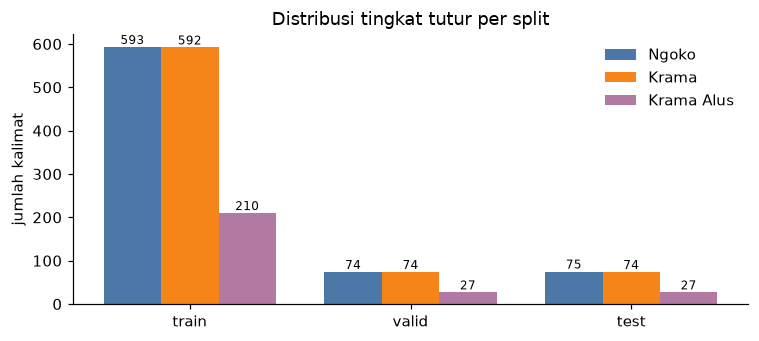

porsi Krama Alus di train: 15,1%


In [5]:
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(3); w = 0.26
for i, lv in enumerate(LV):
    v = [int((SPLIT[sp].level == lv).sum()) for sp in SPLIT]
    b = ax.bar(x + (i - 1) * w, v, w, color=WARNA[lv], label=NAMA[lv])
    ax.bar_label(b, fontsize=8)
ax.set_xticks(x, ["train", "valid", "test"]); ax.set_ylabel("jumlah kalimat")
ax.set_title("Distribusi tingkat tutur per split"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()
p_ka = (TRAIN.level == "krama_alus").mean()
print(f"porsi Krama Alus di train: {koma(100 * p_ka, 1)}%")

**Temuan:** Krama Alus hanya sekitar 15% dari data train, sedangkan Ngoko dan Krama masing-masing sekitar 42%.
**Dampak:** model akan lebih jarang melihat Krama Alus. Karena itu, di bagian 5 kalimat Krama Alus di-oversample tiga
kali, dan ketepatan dilaporkan per tingkat, bukan hanya rata-rata.

### 4.2 Panjang kalimat

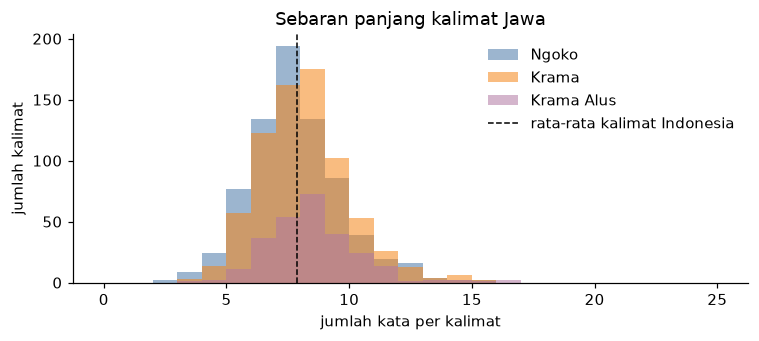

,Rata-rata kata,Median,Maksimum
Ngoko,7.31,7.0,15
Krama,7.67,8.0,15
Krama Alus,8.02,8.0,16


In [6]:
semua = pd.concat([TRAIN, VALID, TEST])
semua["kata_jawa"] = semua.javanese.str.split().str.len()
semua["kata_indonesia"] = semua.indonesian.str.split().str.len()
fig, ax = plt.subplots(figsize=(7, 3.2))
bins = np.arange(0, 26)
for lv in LV:
    ax.hist(semua[semua.level == lv].kata_jawa, bins=bins, alpha=0.55, color=WARNA[lv], label=NAMA[lv])
ax.axvline(semua.kata_indonesia.mean(), color="black", ls="--", lw=1, label="rata-rata kalimat Indonesia")
ax.set_xlabel("jumlah kata per kalimat"); ax.set_ylabel("jumlah kalimat"); ax.legend(frameon=False)
ax.set_title("Sebaran panjang kalimat Jawa"); plt.tight_layout(); plt.show()
ringkas = semua.groupby("level").kata_jawa.agg(["mean", "median", "max"]).reindex(LV)
ringkas.index = [NAMA[l] for l in ringkas.index]
ringkas.columns = ["Rata-rata kata", "Median", "Maksimum"]
display(ringkas.round(2))

**Temuan:** kalimat sangat pendek (rata-rata sekitar 8 kata, hampir tidak ada yang lebih dari 20 kata).
**Dampak:** panjang maksimum input dan output cukup 64 token, dan model tidak diuji untuk kalimat panjang atau
teks teknis. Ini dicatat sebagai keterbatasan.

### 4.3 Kualitas teks (noise)

In [7]:
cek = []
for kol in ["indonesian", "javanese"]:
    s = df[kol].astype(str)
    cek += [(kol, "nilai kosong", int(df[kol].isna().sum())),
            (kol, "spasi di awal atau akhir", int((s != s.str.strip()).sum())),
            (kol, "spasi ganda", int(s.str.contains("  ").sum())),
            (kol, "bukan bentuk Unicode NFC", int((s != s.map(lambda t: unicodedata.normalize("NFC", t))).sum()))]
cek.append(("javanese", "baris identik (grup, tingkat, kalimat)", int(df.duplicated(["group", "label", "javanese"]).sum())))
noise = pd.DataFrame(cek, columns=["Kolom", "Jenis masalah", "Jumlah baris"])
noise["Persen dari seluruh baris"] = (100 * noise["Jumlah baris"] / len(df)).map(lambda v: koma(v, 2) + "%")
display(noise)

,Kolom,Jenis masalah,Jumlah baris,Persen dari seluruh baris
0,indonesian,nilai kosong,0,"0,00%"
1,indonesian,spasi di awal atau akhir,1321,"65,75%"
2,indonesian,spasi ganda,6,"0,30%"
3,indonesian,bukan bentuk Unicode NFC,0,"0,00%"
4,javanese,nilai kosong,0,"0,00%"
5,javanese,spasi di awal atau akhir,0,"0,00%"
6,javanese,spasi ganda,0,"0,00%"
7,javanese,bukan bentuk Unicode NFC,0,"0,00%"
8,javanese,"baris identik (grup, tingkat, kalimat)",0,"0,00%"


**Temuan:** noise sangat sedikit (di bawah 1% baris).
**Dampak:** normalisasi teks hampir tidak mengubah data, sehingga tidak diharapkan memengaruhi hasil. Ini dibuktikan
di bagian 5.2.

### 4.4 Kosakata dan kata yang tidak muncul di data train

In [8]:
kosakata_train = Counter(w for s in TRAIN.javanese for w in token(s))
baris = []
for nama, d in [("valid", VALID), ("test", TEST)]:
    for lv in LV + ["all"]:
        dd = d if lv == "all" else d[d.level == lv]
        tok = [w for s in dd.javanese for w in token(s)]
        baris.append((nama, NAMA[lv], len(tok), 100 * np.mean([w not in kosakata_train for w in tok])))
oov = pd.DataFrame(baris, columns=["Split", "Tingkat", "Jumlah token referensi", "Persen token tidak ada di train"])
oov["Persen token tidak ada di train"] = oov["Persen token tidak ada di train"].map(lambda v: koma(v, 1) + "%")
print("ukuran kosakata train:", len(kosakata_train), "kata unik")
display(oov)

ukuran kosakata train: 2814 kata unik


,Split,Tingkat,Jumlah token referensi,Persen token tidak ada di train
0,valid,Ngoko,566,"24,9%"
1,valid,Krama,589,"22,4%"
2,valid,Krama Alus,227,"19,4%"
3,valid,Semua,1382,"22,9%"
4,test,Ngoko,562,"26,7%"
5,test,Krama,571,"23,6%"
6,test,Krama Alus,208,"18,3%"
7,test,Semua,1341,"24,1%"


**Temuan:** sekitar seperlima token di kalimat referensi valid dan test tidak pernah muncul di data train.
**Dampak:** model harus menebak kata yang belum pernah dilihatnya dalam bahasa Jawa. Ini kandidat utama pembatas
kualitas, dan diuji lagi di bagian 7.2 (learning curve per ukuran data) dan 10.1 (F1-score per frekuensi kata).

### 4.5 Seberapa mirip tingkat-tingkat itu satu sama lain?

Untuk setiap grup yang punya dua tingkat, kalimat Jawa satu tingkat dibandingkan dengan tingkat lain memakai chrF++.
Nilai tinggi berarti kedua tingkat hanya berbeda sedikit kata.

In [9]:
pasang = {("ngoko", "krama"): [], ("krama", "krama_alus"): [], ("ngoko", "krama_alus"): []}
for _, g in TRAIN.groupby("group"):
    jv = dict(zip(g.level, g.javanese))
    for a, b in pasang:
        if a in jv and b in jv:
            pasang[(a, b)].append(sacrebleu.sentence_chrf(jv[a], [jv[b]], word_order=2).score)
mirip = pd.DataFrame([(f"{NAMA[a]} vs {NAMA[b]}", len(v), np.mean(v)) for (a, b), v in pasang.items()],
                     columns=["Pasangan tingkat", "Jumlah grup", "Rata-rata chrF++ antar tingkat"])
mirip["Rata-rata chrF++ antar tingkat"] = mirip["Rata-rata chrF++ antar tingkat"].map(koma)
display(mirip)

,Pasangan tingkat,Jumlah grup,Rata-rata chrF++ antar tingkat
0,Ngoko vs Krama,592,"32,88"
1,Krama vs Krama Alus,206,"54,38"
2,Ngoko vs Krama Alus,207,"26,96"


**Temuan:** Krama dan Krama Alus jauh lebih mirip satu sama lain daripada Ngoko dan Krama. Perbedaannya sering
hanya beberapa kata hormat (misalnya *sampeyan* → *panjenengan*, *nedha* → *dhahar*).
**Dampak:** kesalahan yang paling mungkin adalah Krama Alus yang "jatuh" menjadi Krama. Karena itu model diberi data
tambahan Krama → Krama Alus (multi-task, bagian 5.5), dan analisis memakai confusion matrix (bagian 9.4).

### 4.6 Kata khas tiap tingkat: wordcloud dibandingkan log-odds

Wordcloud menampilkan kata dengan ukuran sesuai frekuensinya. Kekurangannya: kata yang sering muncul di **kedua**
tingkat juga tampil besar, sehingga wordcloud tidak menunjukkan kata mana yang membedakan tingkat.

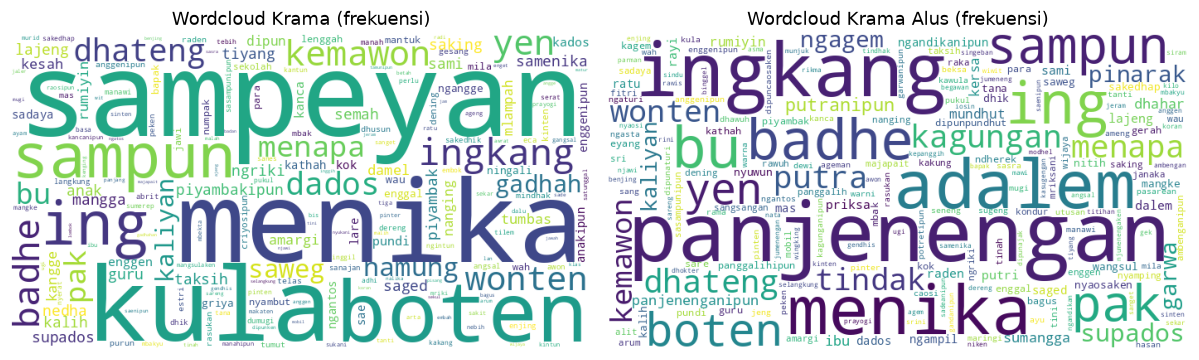

In [10]:
from wordcloud import WordCloud
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, lv in zip(axs, ["krama", "krama_alus"]):
    frek = Counter(w for s in TRAIN[TRAIN.level == lv].javanese for w in token(s))
    wc = WordCloud(width=700, height=380, background_color="white", random_state=42, colormap="viridis")
    ax.imshow(wc.generate_from_frequencies(frek)); ax.axis("off"); ax.set_title(f"Wordcloud {NAMA[lv]} (frekuensi)")
plt.tight_layout(); plt.show()

Kedua wordcloud di atas didominasi kata yang sama (misalnya *sampun*, *ingkang*, *boten*), sehingga perbedaan
Krama dan Krama Alus sulit dilihat. Sebagai gantinya dipakai **weighted log-odds dengan prior Dirichlet**
(Monroe dkk., 2008). Metode ini mengukur seberapa jauh frekuensi relatif sebuah kata berbeda di dua kelompok, lalu
membaginya dengan ketidakpastiannya, sehingga kata langka tidak mendapat skor berlebihan.

Supaya perbandingannya adil, hanya dipakai pasangan kalimat dari grup yang sama (isi kalimatnya sama, hanya
tingkatnya berbeda). Skor positif berarti khas Krama Alus, negatif berarti khas Krama.

In [11]:
kunci = TRAIN[TRAIN.level.isin(["krama", "krama_alus"])].groupby(["group", "indonesian"])["level"].agg(list)
kunci = kunci[kunci.map(sorted) == ["krama", "krama_alus"]].index
sub = TRAIN.set_index(["group", "indonesian"]).loc[kunci].reset_index()
print("jumlah pasangan Krama–Krama Alus dengan isi sama:", len(kunci))

def log_odds(teks_a, teks_b, alpha=0.1, min_frek=5):
    ca = Counter(w for s in teks_a for w in token(s)); cb = Counter(w for s in teks_b for w in token(s))
    prior = {w: alpha * (ca[w] + cb[w]) for w in set(ca) | set(cb)}
    na, nb, a0 = sum(ca.values()), sum(cb.values()), sum(prior.values())
    hasil = {}
    for w, a in prior.items():
        if ca[w] + cb[w] < min_frek: continue
        la = math.log((ca[w] + a) / (na + a0 - ca[w] - a)); lb = math.log((cb[w] + a) / (nb + a0 - cb[w] - a))
        hasil[w] = ((la - lb) / math.sqrt(1 / (ca[w] + a) + 1 / (cb[w] + a)), ca[w], cb[w])
    return hasil

ka = sub[sub.level == "krama_alus"].javanese; kr = sub[sub.level == "krama"].javanese
skor = log_odds(ka, kr)
urut = sorted(skor.items(), key=lambda kv: kv[1][0])
pilih = urut[:10] + urut[-10:]
fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.barh([w for w, _ in pilih], [v[0] for _, v in pilih],
        color=[WARNA["krama_alus"] if v[0] > 0 else WARNA["krama"] for _, v in pilih])
for i, (w, v) in enumerate(pilih):
    ax.text(v[0] + (0.2 if v[0] > 0 else -0.2), i, f"{v[1]} / {v[2]}", va="center", ha="left" if v[0] > 0 else "right", fontsize=8)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("z-score log-odds (positif = khas Krama Alus, negatif = khas Krama)")
ax.set_title("Kata paling khas: Krama Alus dibanding Krama\n(angka = frekuensi di Krama Alus / frekuensi di Krama)")
plt.tight_layout(); plt.show()

# cek kestabilan: skor dihitung ulang di dua belahan data, tanda harus sama
skor_belahan = []
for bagian in [kunci[0::2], kunci[1::2]]:
    sb = TRAIN.set_index(["group", "indonesian"]).loc[bagian].reset_index()
    skor_belahan.append(log_odds(sb[sb.level == "krama_alus"].javanese, sb[sb.level == "krama"].javanese, min_frek=1))
stabil = []
for w, v in urut[-5:][::-1] + urut[:5]:
    tanda = [np.sign(s.get(w, (0,))[0]) for s in skor_belahan]
    stabil.append((w, "Krama Alus" if v[0] > 0 else "Krama", "stabil" if tanda[0] == tanda[1] == np.sign(v[0]) else "tidak stabil"))
display(pd.DataFrame(stabil, columns=["Kata", "Khas untuk", "Arah skor di dua belahan data"]))

ValueError: ('Lengths must match to compare', (597,), (2,))

**Temuan:** kata hormat seperti *panjenengan* dan *adalem* sama sekali tidak muncul di Krama (frekuensi 0), sedangkan
*kula* (aku, Krama) hampir hilang di Krama Alus. Pembeda tingkat ada pada **kata ganti dan kata kerja tertentu**,
bukan pada struktur kalimat.
**Dampak:** penanda tingkat adalah kata-kata pendek yang sering muncul. Preprocessing yang membuang kata umum
(stopword removal) akan membuang justru penanda ini (dibuktikan di bagian 5.3).

## 5. Preprocessing: sebelum dan sesudah

Pada penerjemahan mesin dengan model berbasis subword, preprocessing berbeda dari klasifikasi teks. Model memakai
tokenizer SentencePiece yang sudah menangani huruf, tanda baca, dan imbuhan, sehingga teks tidak perlu
"dibersihkan" secara agresif. Yang penting justru **cara membagi data** dan **cara menyusun data training**. Setiap
langkah di bawah ditunjukkan dalam bentuk sebelum dan sesudah.

### 5.1 Pembagian data: split acak dibanding split per grup

Satu kalimat Indonesia muncul di beberapa baris (satu per tingkat). Jika data dibagi secara acak per baris, kalimat
Indonesia yang sama bisa masuk ke train **dan** test sekaligus, sehingga model "sudah melihat" soal ujiannya.

In [ ]:
rng = np.random.default_rng(42)
d3 = df[df.label.isin([0, 2, 3])].reset_index(drop=True)
acak = rng.permutation(len(d3)); n_test = int(0.1 * len(d3))
uji_acak, latih_acak = d3.iloc[acak[:n_test]], d3.iloc[acak[n_test:]]
bocor_acak = uji_acak.indonesian.str.strip().str.lower().isin(set(latih_acak.indonesian.str.strip().str.lower())).mean()
bocor_grup = TEST.indonesian.str.strip().str.lower().isin(set(TRAIN.indonesian.str.strip().str.lower())).mean()
grup_sama = len(set(TEST.group) & set(TRAIN.group))
display(pd.DataFrame([
    ("Sebelum: split acak per baris (90/10)", koma(100 * bocor_acak, 1) + "%", "ya"),
    ("Sesudah: split per grup (dipakai)", koma(100 * bocor_grup, 1) + "%", f"tidak ({grup_sama} grup sama)"),
], columns=["Cara pembagian", "Kalimat Indonesia test yang juga ada di train", "Ada kebocoran?"]))

**Hasil:** dengan split acak, sebagian besar kalimat test sudah ada di train, sehingga skor akan terlihat tinggi
padahal model hanya mengingat. Proyek ini memakai **split per grup** (`scripts/split_data.py`): satu grup utuh
masuk ke satu split saja. Akibatnya, skor proyek ini tidak bisa dibandingkan langsung dengan penelitian yang memakai
split acak (misalnya Prayoga dkk., 2026, chrF++ 56,39 pada M2M100), karena skor mereka kemungkinan terangkat oleh
kebocoran ini.

### 5.2 Normalisasi ringan teks

In [ ]:
def normalisasi(s):
    return re.sub(r"\s+", " ", unicodedata.normalize("NFC", str(s))).strip()
berubah = {kol: int((df[kol].astype(str) != df[kol].map(normalisasi)).sum()) for kol in ["indonesian", "javanese"]}
contoh_ubah = df[df.javanese.astype(str) != df.javanese.map(normalisasi)].javanese.head(3).tolist()
display(pd.DataFrame([(k, v, koma(100 * v / len(df), 2) + "%") for k, v in berubah.items()],
                     columns=["Kolom", "Baris yang berubah", "Persen"]))
for s in contoh_ubah:
    print("sebelum:", repr(s)); print("sesudah:", repr(normalisasi(s)))

**Hasil:** normalisasi (Unicode NFC, merapikan spasi) hanya mengubah segelintir baris, dan perubahannya hanya spasi.
Tokenizer model sudah mengabaikan perbedaan spasi seperti ini, jadi langkah ini aman tetapi tidak berpengaruh pada skor.

### 5.3 Mengapa stopword removal, stemming, dan lowercase tidak dipakai

Di klasifikasi teks, kata umum (stopword) sering dibuang. Di proyek ini, kata umum justru membawa tingkat tutur.
Tabel berikut menampilkan 15 kata paling sering per tingkat, dan menandai mana yang merupakan **penanda tingkat**
(daftar penanda yang dipakai saat training).

In [ ]:
PENANDA = {"kowe", "aku", "awakmu", "mangan", "lunga", "turu", "sampeyan", "kula", "menika", "punika", "boten",
           "nedha", "kesah", "tilem", "panjenengan", "panjenenganipun", "dalem", "adalem", "dhahar", "tindak",
           "kagungan", "sare", "wis", "sampun", "ora", "mboten"}
kolom = {}
for lv in LV:
    frek = Counter(w for s in TRAIN[TRAIN.level == lv].javanese for w in token(s)).most_common(15)
    kolom[NAMA[lv]] = [f"{w} ★" if w in PENANDA else w for w, _ in frek]
display(pd.DataFrame(kolom, index=range(1, 16)))
jumlah = {NAMA[lv]: sum("★" in w for w in kolom[NAMA[lv]]) for lv in LV}
print("jumlah penanda tingkat di 15 kata tersering:", jumlah, " (★ = penanda tingkat)")

**Hasil:** sebagian kata tersering adalah penanda tingkat (bertanda ★). Membuang stopword berarti membuang informasi
yang paling dibutuhkan. Alasan lain:

- **Stemming** menghapus imbuhan seperti *-ipun* dan *dipun-*, padahal imbuhan itu adalah ciri Krama
  (misalnya *dipunbekta*). Model juga harus *menghasilkan* kalimat lengkap, bukan hanya membaca.
- **Lowercase** tidak dipakai karena output harus berupa kalimat yang benar (huruf kapital di awal dan pada nama),
  dan chrF++ membedakan huruf besar dan kecil.

### 5.4 Source tag: menandai tingkat yang diminta

Tingkat yang diinginkan ditulis sebagai token khusus di awal kalimat Indonesia (Sennrich dkk., 2016). Embedding
setiap tag diinisialisasi dari rata-rata embedding beberapa kata penandanya, supaya model tidak mulai dari nol.

In [ ]:
TAG = {l: f"<{l}>" for l in LV}
INIT_WORDS = {"ngoko": "kowe aku mangan lunga turu", "krama": "sampeyan kula nedha kesah tilem",
              "krama_alus": "panjenenganipun dalem dhahar tindak sare"}
g = TRAIN.groupby("group").filter(lambda x: set(x.level) == set(LV)).groupby("group").head(3).head(3)
display(pd.DataFrame({"Sebelum (input asli)": g.indonesian.values,
                      "Sesudah (input ke model)": [f"{TAG[l]} {s}" for s, l in zip(g.indonesian, g.level)],
                      "Target Jawa": g.javanese.values}))
display(pd.DataFrame([(TAG[l], INIT_WORDS[l]) for l in LV], columns=["Tag", "Kata untuk inisialisasi embedding"]))

### 5.5 Oversampling Krama Alus dan data multi-task

Dua perlakuan untuk mengatasi sedikitnya data Krama Alus:

1. **Oversampling 3 kali**: setiap pasangan Krama Alus dimasukkan tiga kali ke data training.
2. **Multi-task Krama → Krama Alus**: untuk grup yang punya Krama dan Krama Alus, ditambahkan pasangan
   *Jawa Krama → Jawa Krama Alus*. Model belajar langsung kata mana yang harus diganti agar menjadi lebih halus.

In [ ]:
OVERSAMPLE = 3
sebelum = TRAIN.level.value_counts().reindex(LV)
sesudah = sebelum.copy(); sesudah["krama_alus"] *= OVERSAMPLE
multitask = []
for _, g in TRAIN.groupby("group"):
    jv = dict(zip(g.level, g.javanese))
    if "krama" in jv and "krama_alus" in jv and jv["krama"] != jv["krama_alus"]:
        multitask.append((f"{TAG['krama_alus']} {jv['krama']}", jv["krama_alus"]))
tabel = pd.DataFrame({"Sebelum": sebelum, f"Sesudah oversampling {OVERSAMPLE} kali": sesudah}).rename(index=NAMA)
tabel.loc["Pasangan multi-task Krama → Krama Alus"] = [0, len(multitask)]
tabel.loc["Jumlah pasangan training"] = [sebelum.sum(), sesudah.sum() + len(multitask)]
display(tabel)
fig, ax = plt.subplots(figsize=(7, 3))
x = np.arange(3)
ax.bar(x - 0.2, sebelum.values, 0.4, color="#BBBBBB", label="sebelum")
ax.bar(x + 0.2, sesudah.values, 0.4, color=[WARNA[l] for l in LV], label="sesudah oversampling")
ax.set_xticks(x, [NAMA[l] for l in LV]); ax.set_ylabel("pasangan Indonesia → Jawa"); ax.legend(frameon=False)
ax.set_title("Data training sebelum dan sesudah oversampling"); plt.tight_layout(); plt.show()
print("contoh pasangan multi-task:"); print("  input :", multitask[0][0]); print("  target:", multitask[0][1])

### 5.6 Ringkasan preprocessing

| Langkah | Sebelum | Sesudah | Dipakai? | Alasan |
|---|---|---|---|---|
| Pembagian data | split acak per baris | split per grup | ya | mencegah kalimat test bocor ke train |
| Normalisasi spasi dan Unicode | teks asli | teks rapi | ya (tidak berpengaruh) | noise sangat sedikit |
| Stopword removal, stemming, lowercase | – | – | tidak | membuang penanda tingkat; output harus kalimat lengkap |
| Source tag | `Kamu sudah makan?` | `<krama_alus> Kamu sudah makan?` | ya | cara memilih tingkat |
| Oversampling Krama Alus | 1 kali | 3 kali | ya | Krama Alus paling sedikit |
| Multi-task Krama → Krama Alus | tidak ada | ada | ya | Krama Alus paling mirip Krama |

Pengaruh setiap langkah terhadap hasil model ditunjukkan di bagian 9 (tabel perbandingan model).

## 6. Modelling

### 6.1 Model yang dicoba

Eksperimen disusun bertahap: setiap baris menambahkan satu perubahan ke baris sebelumnya, sehingga pengaruh setiap
perubahan bisa dilihat (bagian 9).

| No. | Model | Perubahan dibanding sebelumnya | Kernel Kaggle |
|---|---|---|---|
| 1 | Salin input | batas bawah: kalimat Indonesia disalin tanpa diterjemahkan | `unggah-ungguh-zero-shot-baseline` |
| 2 | M2M100-418M zero-shot | model multibahasa tanpa fine-tuning (Fan dkk., 2021) | sama |
| 3 | NLLB-200-600M zero-shot | model multibahasa tanpa fine-tuning (NLLB Team, 2024) | sama |
| 4 | M2M100 fine-tuning tanpa tag | dilatih pada data, tetapi tingkat tidak bisa dipilih (4 tingkat) | `unggah-ungguh-finetune-m2m100` |
| 5 | M2M100 + source tag | tag tingkat di input (4 tingkat) | sama |
| 6 | NLLB-600M + source tag | sama dengan no. 5, model berbeda | `unggah-ungguh-finetune-nllb` |
| 7 | M2M100 + tag, 3 tingkat | target hanya Ngoko, Krama, Krama Alus (rata-rata 3 seed) | `unggah-ungguh-finetune-3lv-m2m100` |
| 8 | + inisialisasi embedding tag + oversampling | perlakuan data bagian 5.4 dan 5.5 (rata-rata 3 seed) | sama |
| 9 | NLLB-600M + inisialisasi + oversampling + multi-task | pembanding model lain (rata-rata 3 seed) | `unggah-ungguh-finetune-3lv-nllb` |
| 10 | Resep final, beam search 4 | + multi-task, 15 epoch, pemilihan checkpoint gabungan | `unggah-ungguh-final-3lv-v2` |
| 11 | **Resep final + rerank (model final)** | + 8 kandidat dipilih ulang oleh classifier tingkat | sama |
| 12–17 | variasi sesudah model final | data Ngoko Alus, data tambahan, self-training, post-editing, Cendol mT5 | beberapa kernel |

### 6.2 Hyperparameter model final

In [ ]:
ringkasan_v2 = json.load(open(f"{K}/final_3lv_v2/output/summary_v2.json", encoding="utf-8"))
hp = ringkasan_v2["hparams"]
display(pd.DataFrame([
    ("Model dasar", "facebook/m2m100_418M"),
    ("Jumlah epoch", hp["epochs"]), ("Batch size", hp["bs"]), ("Learning rate", hp["lr"]),
    ("Warmup", f"{int(100 * hp['warmup'])}% langkah pertama, lalu turun linear"),
    ("Optimizer", "AdamW, weight decay 0,01, gradient clipping 1,0, mixed precision fp16"),
    ("Panjang maksimum", f"{hp['maxlen']} token"), ("Oversampling Krama Alus", f"{hp['os']} kali"),
    ("Seed", hp["seed"]), ("Skor pemilihan checkpoint", f"chrF++ + {int(hp['ctrl_weight'])} × ketepatan tingkat (data validasi)"),
    ("Kandidat untuk rerank", f"{hp['nbest']} (beam search)"), ("Bobot rerank yang dicoba", ", ".join(koma(x, 1) for x in hp["lams"])),
    ("Classifier rerank", ringkasan_v2["reranker"]["base"]), ("Classifier penilai (berbeda)", ringkasan_v2["judge"]["base"]),
], columns=["Pengaturan", "Nilai"]).astype(str))

### 6.3 Kode training inti

Kode berikut adalah inti training dari kernel `unggah-ungguh-final-3lv-v2` (diringkas). Kode ini **tidak dijalankan**
di notebook ini karena membutuhkan GPU sekitar 15 menit per model. Hasilnya (log, metrics, prediksi) dimuat dari
dataset dan dihitung ulang di bagian berikutnya.

```python
# 1. siapkan data: tag + oversampling Krama Alus + pasangan multi-task Krama -> Krama Alus
base = [(f"<{l}> {s}", t, l) for s, l, t in zip(tr.indonesian, tr.level, tr.javanese)]
id_pairs = [(s, t) for s, t, _ in base] + [(s, t) for s, t, l in base if l == "krama_alus"] * (OS - 1)
jv_pairs = honor_pairs()   # (<krama_alus> kalimat Krama, kalimat Krama Alus) dari grup yang sama

# 2. model: tambah token tag, embedding tag = rata-rata embedding kata penanda
tok.add_tokens(["<ngoko>", "<krama>", "<krama_alus>"], special_tokens=True)
model.resize_token_embeddings(len(tok))
emb[tag_id] = emb[ids_kata_penanda].mean(0)

# 3. training: AdamW + warmup linear, fp16, 15 epoch
for epoch in range(15):
    for batch in make_batches():          # campuran batch Indonesia->Jawa dan Jawa->Jawa
        loss = cross_entropy(model(**batch).logits, labels)
        loss.backward(); clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
    # 4. evaluasi di VALID: chrF++ (greedy) dan ketepatan tingkat; simpan checkpoint dengan skor tertinggi
    skor = chrf(hyp_valid, ref_valid) + 30 * ketepatan_tingkat(hyp_valid)

# 5. decoding: 8 kandidat beam search, dipilih ulang dengan
#    skor = log-prob model + lambda * log P(tingkat diminta | kandidat)  (classifier RoBERTa Jawa)
```

### 6.4 Rerank kandidat

Model menghasilkan 8 kandidat terjemahan dengan beam search. Setiap kandidat dinilai oleh classifier tingkat
`w11wo/javanese-roberta-small`, lalu dipilih kandidat dengan skor gabungan tertinggi. Classifier untuk rerank
**sengaja dibedakan** dari classifier penilai (`w11wo/javanese-distilbert-small`). Jika keduanya sama, model akan
"menyontek" penilainya dan ketepatan tingkat akan naik palsu. Bobot λ dipilih di data validasi:

In [ ]:
v = ringkasan_v2["runs"]["m2m_base"]["valid"]
display(pd.DataFrame([(("beam search 4 (tanpa rerank)" if k == "beam4" else f"rerank, λ = {koma(float(k[6:]), 1)}"),
                       koma(x["chrF++"]), koma(x["ctrl"], 3), koma(x["ctrl_lv"]["krama_alus"], 3), koma(x["score"]))
                      for k, x in v.items()],
                     columns=["Decoding (data validasi)", "chrF++", "Ketepatan tingkat", "Ketepatan Krama Alus", "Skor pemilihan"]))
print("dipilih:", ringkasan_v2["runs"]["m2m_base"]["best_decode"])

## 7. Learning curve

Ada dua jenis learning curve yang menjawab dua pertanyaan berbeda:

- **Per epoch** (7.1): bagaimana model belajar selama training? Kapan berhenti membaik?
- **Per ukuran data** (7.2 dan 7.3): apakah menambah data masih membantu?

### 7.1 Learning curve per epoch (model final)

In [ ]:
m2m = json.load(open(f"{K}/final_3lv_v2/output/metrics_m2m_base.json", encoding="utf-8"))
H = pd.DataFrame(m2m["history"])
H["ketepatan_krama_alus"] = H.valid_ctrl_lv.map(lambda d: d["krama_alus"])
terpilih = m2m["best_epoch"]
assert len(H) == 15 and H.loc[H.score.idxmax(), "epoch"] == terpilih

fig, axs = plt.subplots(3, 1, figsize=(7.5, 7.5), sharex=True)
axs[0].plot(H.epoch, H.train_loss, "-o", color="#444444", ms=4); axs[0].set_yscale("log")
axs[0].set_ylabel("train loss (skala log)"); axs[0].set_title("Learning curve per epoch, M2M100 resep final")
axs[1].plot(H.epoch, H["valid_chrF++"], "-o", color="#C0392B", ms=4); axs[1].set_ylabel("chrF++ validasi\n(greedy)")
axs[2].plot(H.epoch, 100 * H.valid_ctrl, "-o", color="#222222", ms=4, label="semua tingkat")
axs[2].plot(H.epoch, 100 * H.ketepatan_krama_alus, "-s", color=WARNA["krama_alus"], ms=4, label="Krama Alus")
axs[2].set_ylabel("ketepatan tingkat\nvalidasi (%)"); axs[2].set_xlabel("epoch"); axs[2].legend(frameon=False)
for ax in axs:
    ax.axvline(terpilih, color="#2E8B57", ls="--", lw=1)
axs[1].annotate(f"epoch {terpilih} terpilih\nskor {koma(H.score[terpilih - 1])} (epoch 12: {koma(H.score[11])})",
                (terpilih, H['valid_chrF++'][terpilih - 1]), xytext=(-150, -45), textcoords="offset points",
                arrowprops=dict(arrowstyle="->", color="#2E8B57"), fontsize=8)
axs[2].set_xticks(range(1, 16)); plt.tight_layout(); plt.show()
tampil = H[H.epoch.isin([1, 4, 10, 12, 14, 15])][["epoch", "train_loss", "valid_chrF++", "valid_ctrl", "ketepatan_krama_alus", "score"]]
tampil.columns = ["Epoch", "Train loss", "chrF++ validasi", "Ketepatan tingkat", "Ketepatan Krama Alus", "Skor pemilihan"]
display(tampil.round(4))

**Cara membaca:**

- **Kontrol tingkat dipelajari cepat.** Ketepatan tingkat sudah 92% di epoch 4 dan setelah itu hampir datar.
  Namun Krama Alus baru mencapai puncaknya di epoch 10, jadi angka rata-rata menyembunyikan tingkat yang paling sulit.
- **Kualitas terjemahan dipelajari lebih lambat.** chrF++ validasi terus naik sampai sekitar epoch 10, lalu datar
  di sekitar 61–62.
- **Checkpoint terpilih adalah epoch 14**, unggul tipis dari epoch 12 (selisih skor 0,04). Epoch 14 punya ketepatan
  Krama Alus validasi lebih rendah daripada epoch 10, karena skor pemilihan memakai ketepatan semua tingkat.
  Aturan ini ditetapkan sebelum melihat data test, jadi tidak diubah.
- **Batasan:** log training tidak mencatat loss validasi, sehingga overfitting tidak bisa dinilai dari loss. Yang bisa
  dikatakan hanya bahwa chrF++ validasi tidak turun sampai epoch 15. Ketepatan di grafik ini dinilai classifier
  bawaan kernel, bukan classifier penilai tetap.

### 7.2 Learning curve per ukuran data

Resep final dilatih ulang dengan 25%, 50%, 75%, dan 100% data train (subset diambil per grup dan seimbang per tingkat,
dua subset acak untuk 25–75%). Semua dievaluasi di data validasi saja. chrF++ dihitung ulang di sini dari prediksi
tersimpan, dan ketepatan tingkat dinilai oleh classifier penilai tetap.

In [ ]:
lc_lokal = json.load(open(f"{K}/learning_curve_v2/analisis_lokal.json", encoding="utf-8"))
baris = []
for f in sorted(glob.glob(f"{K}/learning_curve_v2/output/valid_f*.csv")):
    nama = os.path.basename(f)[6:-4]; d = pd.read_csv(f); d = d[d.level.isin(LV)]
    h = d.hyp.fillna("").astype(str).values; r = d.javanese.values
    ok = vonis_juri(h) == d.level.values
    baris.append({"run": nama, "persen": int(round(100 * lc_lokal[nama]["frac"])), "kalimat_train": lc_lokal[nama]["n_kalimat"],
                  "all": chrf(h, r), **{lv: chrf(h[d.level == lv], r[d.level == lv]) for lv in LV},
                  "ketepatan": ok.mean(), "ketepatan_krama_alus": ok[d.level.values == "krama_alus"].mean(),
                  "token_tidak_di_train": 100 * lc_lokal[nama]["oov_ref_token"]["all"]})
    assert abs(baris[-1]["all"] - lc_lokal[nama]["chrF++"]["all"]) < 0.02, nama
LC = pd.DataFrame(baris)
rata = LC.groupby("kalimat_train").mean(numeric_only=True).reset_index()

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for lv in ["all"] + LV:
    axs[0].plot(rata.kalimat_train, rata[lv], "-o", color=WARNA[lv], lw=2 if lv == "all" else 1.2, ms=4, label=NAMA[lv])
    axs[0].scatter(LC.kalimat_train, LC[lv], color=WARNA[lv], s=10, alpha=0.4)
axs[0].set_xscale("log", base=2); axs[0].set_xticks(rata.kalimat_train, [f"{n}" for n in rata.kalimat_train])
axs[0].set_xlabel("jumlah kalimat train"); axs[0].set_ylabel("chrF++ validasi"); axs[0].legend(frameon=False, fontsize=8)
axs[0].set_title("Kualitas terjemahan terus naik")
axs[1].plot(rata.kalimat_train, 100 * rata.ketepatan_krama_alus, "-s", color=WARNA["krama_alus"], label="ketepatan Krama Alus")
axs[1].plot(rata.kalimat_train, rata.token_tidak_di_train, "-^", color="#777777", label="token referensi yang tidak ada di train")
axs[1].set_xscale("log", base=2); axs[1].set_xticks(rata.kalimat_train, [f"{n}" for n in rata.kalimat_train])
axs[1].set_ylim(0, 105); axs[1].set_xlabel("jumlah kalimat train"); axs[1].set_ylabel("persen"); axs[1].legend(frameon=False, fontsize=8)
axs[1].set_title("Ketepatan tingkat sudah datar sejak 25% data")
plt.tight_layout(); plt.show()
tampil = rata[["persen", "kalimat_train", "all", "krama_alus", "ketepatan_krama_alus", "token_tidak_di_train"]].copy()
tampil.columns = ["Persen data", "Kalimat train", "chrF++ validasi", "chrF++ Krama Alus", "Ketepatan Krama Alus", "Persen token tidak ada di train"]
display(tampil.round(2))

**Cara membaca:** setiap kali data train digandakan, chrF++ validasi naik sekitar 7 poin dan belum menunjukkan tanda
jenuh. Sebaliknya, ketepatan Krama Alus sudah tinggi sejak 25% data. Bersamaan dengan itu, porsi token referensi yang
tidak pernah dilihat model turun dari sekitar 38% menjadi 23%. Artinya, model sudah bisa **mengontrol tingkat** dengan
sedikit data, tetapi masih kekurangan **kosakata** untuk menerjemahkan isi kalimat dengan benar.

### 7.3 Kontrol: apakah kenaikan itu karena data, atau karena jumlah langkah training?

Pada learning curve 7.2, subset kecil juga mendapat langkah training lebih sedikit (epoch sama, batch lebih sedikit).
Jadi kenaikan chrF++ bisa saja karena model dengan data penuh **dilatih lebih lama**, bukan karena datanya lebih banyak
(Sennrich & Zhang, 2019). Untuk mengujinya, subset 50% dilatih dengan **jumlah langkah yang sama** dengan data penuh
(1.905 langkah).

In [ ]:
kl = json.load(open(f"{K}/lc_kontrol_langkah_v1/output/manifest.json", encoding="utf-8"))
kl_lokal = json.load(open(f"{K}/lc_kontrol_langkah_v1/analisis_lokal.json", encoding="utf-8"))
baris = []
for nama, label in [("f050_s0", "50% data, subset 1"), ("f050_s1", "50% data, subset 2"), ("f100", "100% data")]:
    d = pd.read_csv(f"{K}/lc_kontrol_langkah_v1/output/valid_{nama}_akhir.csv"); d = d[d.level.isin(LV)]
    c = chrf(d.hyp.fillna("").astype(str).values, d.javanese.values)
    assert abs(c - kl["runs"][nama]["akhir"]["valid_rerank"]["per_level"]["all"]["chrF++"]) < 0.02
    baris.append((label, kl["runs"][nama]["steps_done"], c))
tabel = pd.DataFrame(baris, columns=["Run", "Langkah training", "chrF++ validasi"])
fig, ax = plt.subplots(figsize=(6, 3))
b = ax.bar(tabel.Run, tabel["chrF++ validasi"], color=["#9DB4CC", "#9DB4CC", "#4C78A8"])
ax.bar_label(b, labels=[koma(x) for x in tabel["chrF++ validasi"]]); ax.set_ylim(50, 66)
ax.set_ylabel("chrF++ validasi"); ax.set_title("Jumlah langkah training disamakan (1.905)"); plt.tight_layout(); plt.show()
tabel["chrF++ validasi"] = tabel["chrF++ validasi"].map(koma)
display(tabel)
for nama, label in [("f050_s0", "subset 1"), ("f050_s1", "subset 2")]:
    lo, hi = kl_lokal[nama]["gap_boot_CI90"]
    print(f"selisih 100% data terhadap 50% data ({label}): {koma(kl['gap_akhir'][nama])} poin chrF++, "
          f"interval kepercayaan 90% (bootstrap per grup): {koma(lo)} sampai {koma(hi)}")

**Hasil:** walaupun jumlah langkah disamakan, model dengan data penuh tetap unggul sekitar 5–8 poin chrF++. Jadi
keunggulan itu memang berasal dari **jumlah data**, bukan dari training yang lebih lama. Batasan: satu seed, hanya
data validasi, dan jumlah token per langkah tidak disamakan.

## 8. Pemilihan checkpoint dan rerank

Semua pemilihan (epoch, metode decoding, bobot rerank, varian model) dilakukan di **data validasi**. Data test hanya
dipakai sekali di akhir untuk dilaporkan. Ini mencegah hasil test terlihat lebih bagus karena dipilih berulang kali.

| Keputusan | Pilihan | Dasar |
|---|---|---|
| Epoch | 14 | skor validasi tertinggi (bagian 7.1) |
| Decoding | rerank, λ = 2,0 | skor validasi tertinggi (bagian 6.4) |
| Varian | M2M100 resep final | skor validasi tertinggi di antara varian kernel `final-3lv-v2` |

## 9. Evaluasi pada data test

### 9.1 Tabel perbandingan semua model

chrF++ dan BLEU dihitung ulang dari file prediksi (176 kalimat test). Ketepatan tingkat dinilai oleh classifier
penilai tetap pada set kontrol: 75 kalimat Indonesia, masing-masing diterjemahkan ke ketiga tingkat (225 permintaan).
Kolom terakhir adalah **selisih chrF++ terhadap model final** beserta **interval kepercayaan 90%** dari paired
bootstrap per grup (1.000 kali; Koehn, 2004). Jika interval itu tidak memuat 0, selisihnya dapat dianggap nyata.

In [ ]:
F3M, F3N, SEEDS = "finetune_3lv_m2m100/output", "finetune_3lv_nllb/output", ["s42", "s13", "s2024"]
MODEL = [  # (kode, kelompok, nama lengkap, file prediksi, kolom hipotesis, file kontrol)
    ("copy", "Batas bawah", "Salin input (tanpa terjemahan)", ["baseline_zeroshot/output/predictions.csv"], "hyp_copy", None),
    ("zs_m2m", "Zero-shot", "M2M100-418M zero-shot", ["baseline_zeroshot/output/predictions.csv"], "hyp_m2m100_418m", None),
    ("zs_nllb", "Zero-shot", "NLLB-200-600M zero-shot", ["baseline_zeroshot/output/predictions.csv"], "hyp_nllb_600m", None),
    ("ft_notag", "Fine-tuning 4 tingkat", "M2M100 fine-tuning tanpa tag", ["finetune_m2m100/output/pred_m2m100_418m_no_tag.csv"], "hyp",
     ["finetune_m2m100/output/control_m2m100_418m_no_tag.csv"]),
    ("ft_tag_m2m", "Fine-tuning 4 tingkat", "M2M100 + source tag", ["finetune_m2m100/output/pred_m2m100_418m_atomic.csv"], "hyp",
     ["finetune_m2m100/output/control_m2m100_418m_atomic.csv"]),
    ("ft_tag_nllb", "Fine-tuning 4 tingkat", "NLLB-600M + source tag", ["finetune_nllb/output/pred_nllb_600m_atomic.csv"], "hyp",
     ["finetune_nllb/output/control_nllb_600m_atomic.csv"]),
    ("r3_base", "Fine-tuning 3 tingkat", "M2M100 + source tag (rata-rata 3 seed)", [f"{F3M}/pred3_m2m100_418m_atomic_base_{s}.csv" for s in SEEDS], "hyp",
     [f"{F3M}/control3_m2m100_418m_atomic_base_{s}.csv" for s in SEEDS]),
    ("r3_initos", "Fine-tuning 3 tingkat", "+ inisialisasi tag + oversampling (rata-rata 3 seed)", [f"{F3M}/pred3_m2m100_418m_atomic_init_os_{s}.csv" for s in SEEDS], "hyp",
     [f"{F3M}/control3_m2m100_418m_atomic_init_os_{s}.csv" for s in SEEDS]),
    ("r3_nllb", "Fine-tuning 3 tingkat", "NLLB-600M + inisialisasi + oversampling + multi-task (rata-rata 3 seed)",
     [f"{F3N}/pred3_nllb_600m_atomic_init_os_mt_{s}.csv" for s in SEEDS], "hyp", [f"{F3N}/control3_nllb_600m_atomic_init_os_mt_{s}.csv" for s in SEEDS]),
    ("v2_beam", "Resep final", "M2M100 resep final, beam search 4", ["final_3lv_v2/output/pred_m2m_base_beam4.csv"], "hyp",
     ["final_3lv_v2/output/control_m2m_base_beam4.csv"]),
    ("final", "Resep final", "M2M100 resep final + rerank (MODEL FINAL)", ["final_3lv_v2/output/pred_m2m_base_rerank2.0.csv"], "hyp",
     ["final_3lv_v2/output/control_m2m_base_rerank2.0.csv"]),
    ("v2_na_ls", "Sesudah model final", "+ data Ngoko Alus + label smoothing + rerank", ["final_3lv_v2/output/pred_m2m_na_ls_rerank1.0.csv"], "hyp",
     ["final_3lv_v2/output/control_m2m_na_ls_rerank1.0.csv"]),
    ("v2_nllb", "Sesudah model final", "NLLB-600M resep final + rerank", ["final_3lv_v2/output/pred_nllb_na_rerank2.0.csv"], "hyp",
     ["final_3lv_v2/output/control_nllb_na_rerank2.0.csv"]),
    ("st", "Sesudah model final", "+ self-training data Krama Alus semu + rerank", ["final_3lv_selftrain/output/pred_st_train_rerank0.5.csv"], "hyp",
     ["final_3lv_selftrain/output/control_st_train_rerank0.5.csv"]),
    ("pe", "Sesudah model final", "Model final + post-editing leksikon Krama Alus", ["final_3lv_postedit/output/pred_rerank2.0_pe_trig_gain.csv"], "hyp",
     ["final_3lv_postedit/output/control_rerank2.0_pe_trig_gain.csv"]),
]

def muat_prediksi(path, kolom):
    d = pd.read_csv(f"{K}/{path}"); d = d[d.level.isin(LV)].reset_index(drop=True)
    assert len(d) == 176 and (d["index"].values == TEST["index"].values).all(), path
    return d[kolom].fillna("").astype(str).values

def muat_kontrol(path):
    d = pd.read_csv(f"{K}/{path}"); d = d[d.requested.isin(LV)].reset_index(drop=True)
    assert len(d) == 225 and not d.duplicated(["indonesian", "requested"]).any(), path
    d["vonis"] = vonis_juri(d.output.fillna("").astype(str)); return d

REF = TEST.javanese.values
HASIL, HYP, KONTROL = {}, {}, {}
for kode, kel, nama, preds, kolom, ctrl in MODEL:
    hs = [muat_prediksi(p, kolom) for p in preds]; HYP[kode] = hs[0]
    r = {"kelompok": kel, "nama": nama, "chrF++": np.mean([chrf(h, REF) for h in hs]), "BLEU": np.mean([bleu(h, REF) for h in hs])}
    for lv in LV:
        m = (TEST.level == lv).values; r[f"chrF++ {lv}"] = np.mean([chrf(h[m], REF[m]) for h in hs])
    if ctrl:
        ks = [muat_kontrol(c) for c in ctrl]; KONTROL[kode] = ks[0]
        r["ketepatan"] = np.mean([(k.vonis == k.requested).mean() for k in ks])
        r["ketepatan krama_alus"] = np.mean([(k.vonis == k.requested)[k.requested == "krama_alus"].mean() for k in ks])
    HASIL[kode] = r
assert abs(HASIL["final"]["chrF++"] - 58.62) < 0.01 and abs(HASIL["final"]["BLEU"] - 33.17) < 0.01
print("model final:", koma(HASIL["final"]["chrF++"]), "chrF++,", koma(HASIL["final"]["BLEU"]), "BLEU,",
      "ketepatan tingkat", koma(HASIL["final"]["ketepatan"], 3))

In [ ]:
# model yang hanya punya angka agregat (prediksi per kalimat tidak tersimpan)
for kode, nama, f, dec, ctrl in [("aug", "+ Krama Alus sintetis dari leksikon + rerank", "metrics_aug.json", "rerank4.0", "control_aug_rerank4.0.csv"),
                                ("nusax", "+ data NusaX (Ngoko) + rerank", "metrics_nusax.json", "rerank2.0", "control_nusax_rerank2.0.csv"),
                                ("aug_nusax", "+ Krama Alus sintetis + NusaX + rerank", "metrics_aug_nusax.json", "rerank0.5", "control_aug_nusax_rerank0.5.csv")]:
    t = json.load(open(f"{K}/final_3lv_merge/output/{f}", encoding="utf-8"))["test"][dec]["test"]
    k = muat_kontrol(f"final_3lv_merge/output/{ctrl}")
    HASIL[kode] = {"kelompok": "Sesudah model final", "nama": nama, "chrF++": t["all"]["chrF++"], "BLEU": t["all"]["BLEU"],
                   **{f"chrF++ {lv}": t[lv]["chrF++"] for lv in LV}, "ketepatan": (k.vonis == k.requested).mean(),
                   "ketepatan krama_alus": (k.vonis == k.requested)[k.requested == "krama_alus"].mean()}
log_cendol = open(f"{K}/final_3lv_cendol_tune/output/kernel_log_v1.json", encoding="utf-8").read().replace("\\n", "\n")
for kode, nama, varian, dec in [("cendol_A", "Cendol mT5-base, nama tingkat di prompt", "A_lvprompt", "beam4"),
                                ("cendol_B", "Cendol mT5-base + oversampling + label smoothing + rerank", "B_os5_ls", "rerank8.0")]:
    m = re.search(rf"{varian} {re.escape(dec)} TEST (\{{[^}}]*\}}) ctrl ([0-9.]+) (\{{[^}}]*\}})", log_cendol)
    t, c = json.loads(m.group(1).replace("'", '"')), json.loads(m.group(3).replace("'", '"'))
    HASIL[kode] = {"kelompok": "Model lain (classifier bawaan kernel)", "nama": nama, "chrF++": t["chrF++"], "BLEU": t["BLEU"],
                   "ketepatan": float(m.group(2)), "ketepatan krama_alus": c["krama_alus"]}

def bootstrap_selisih(h_a, h_b, B=1000, seed=0):
    rng = np.random.default_rng(seed); g = TEST.group.values; ug = np.unique(g)
    idx = {x: np.where(g == x)[0] for x in ug}; beda = []
    for _ in range(B):
        s = np.concatenate([idx[x] for x in rng.choice(ug, len(ug))])
        beda.append(chrf(h_a[s], REF[s]) - chrf(h_b[s], REF[s]))
    return np.percentile(beda, 5), np.percentile(beda, 95)

for kode in HYP:
    if kode != "final":
        HASIL[kode]["interval"] = bootstrap_selisih(HYP[kode], HYP["final"])

URUT = ["copy", "zs_m2m", "zs_nllb", "ft_notag", "ft_tag_m2m", "ft_tag_nllb", "r3_base", "r3_initos", "r3_nllb", "v2_beam", "final",
        "v2_na_ls", "v2_nllb", "nusax", "aug", "aug_nusax", "st", "pe", "cendol_A", "cendol_B"]
baris = []
for i, kode in enumerate(URUT, 1):
    r = HASIL[kode]; sel = r["chrF++"] - HASIL["final"]["chrF++"]
    iv = r.get("interval")
    baris.append((i, r["kelompok"], r["nama"], koma(r["chrF++"]), koma(r["BLEU"]),
                  koma(r.get("ketepatan"), 3), koma(r.get("ketepatan krama_alus"), 3),
                  "acuan" if kode == "final" else (f"{koma(sel)} [{koma(iv[0])} sampai {koma(iv[1])}]" if iv else f"{koma(sel)} (tanpa prediksi per kalimat)")))
TABEL_UTAMA = pd.DataFrame(baris, columns=["No.", "Kelompok", "Model", "chrF++", "BLEU", "Ketepatan tingkat", "Ketepatan Krama Alus",
                                           "Selisih chrF++ terhadap model final [interval kepercayaan 90%]"]).set_index("No.")
display(TABEL_UTAMA)

**Cara membaca tabel (sebelum → sesudah per langkah):**

- Zero-shot → fine-tuning (no. 2–3 → 4): fine-tuning pada data menaikkan chrF++ dari sekitar 20–28 menjadi 42.
- Tanpa tag → dengan tag (no. 4 → 5): lompatan terbesar. chrF++ naik sekitar 13 poin dan ketepatan tingkat naik
  dari 0,33 (sama dengan menebak) menjadi 0,69.
- Inisialisasi tag + oversampling (no. 7 → 8): ketepatan Krama Alus naik paling besar, dari sekitar 0,27 menjadi 0,70.
- Rerank (no. 10 → 11): chrF++ hampir sama, tetapi ketepatan Krama Alus naik lagi.
- Baris 12 ke bawah dijalankan sesudah model final ditetapkan. Beberapa punya chrF++ lebih tinggi (NLLB, NusaX,
  Cendol), tetapi pemilihan tetap dilakukan di data validasi, dan Cendol paling lemah di Krama Alus.
- Baris 4–6 memakai 4 tingkat (termasuk Ngoko Alus) sehingga tidak setara penuh dengan baris 7 ke bawah. Baris Cendol
  dinilai oleh classifier bawaan kernel, bukan classifier penilai tetap.

### 9.2 chrF++ per tingkat

In [ ]:
pilih = ["zs_nllb", "ft_tag_m2m", "r3_initos", "final", "v2_nllb"]
fig, ax = plt.subplots(figsize=(9, 3.6)); x = np.arange(len(pilih)); w = 0.26
for i, lv in enumerate(LV):
    v = [HASIL[k][f"chrF++ {lv}"] for k in pilih]
    b = ax.bar(x + (i - 1) * w, v, w, color=WARNA[lv], label=NAMA[lv]); ax.bar_label(b, labels=[koma(t, 1) for t in v], fontsize=7)
ax.set_xticks(x, ["NLLB\nzero-shot", "M2M100\n+ tag", "+ inisialisasi\n+ oversampling", "MODEL FINAL", "NLLB resep\nfinal"])
ax.set_ylabel("chrF++ test"); ax.legend(frameon=False); ax.set_title("chrF++ per tingkat tutur"); plt.tight_layout(); plt.show()

### 9.3 Trade-off kualitas terjemahan dan ketepatan Krama Alus

Model yang chrF++-nya tinggi belum tentu tepat tingkatnya. Grafik berikut menempatkan setiap model menurut kedua
ukuran itu sekaligus.

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.6))
kel_warna = {"Fine-tuning 4 tingkat": "#9DB4CC", "Fine-tuning 3 tingkat": "#4C78A8", "Resep final": "#C0392B",
             "Sesudah model final": "#2E8B57", "Model lain (classifier bawaan kernel)": "#F58518"}
for i, kode in enumerate(URUT, 1):
    r = HASIL[kode]
    if r.get("ketepatan krama_alus") is None or kode == "pe": continue
    ax.scatter(r["chrF++"], r["ketepatan krama_alus"], s=90 if kode == "final" else 40, color=kel_warna[r["kelompok"]],
               marker="D" if "Model lain" in r["kelompok"] else "o", edgecolor="white", zorder=3)
    ax.annotate(f"{i}" + (" (final)" if kode == "final" else ""), (r["chrF++"], r["ketepatan krama_alus"]), xytext=(5, 3),
                textcoords="offset points", fontsize=8)
for k, c in kel_warna.items(): ax.scatter([], [], color=c, label=k)
ax.set_xlabel("chrF++ test (176 kalimat)"); ax.set_ylabel("ketepatan Krama Alus (75 permintaan)")
ax.legend(frameon=False, fontsize=8, loc="lower right"); ax.set_title("Nomor = nomor baris di tabel 9.1")
plt.tight_layout(); plt.show()

Kanan atas adalah posisi ideal. Model final dan variasinya berkumpul di kanan atas. Cendol (wajik oranye) punya chrF++
tertinggi tetapi ketepatan Krama Alus terendah di antara model fine-tuning terakhir, sehingga tidak dipilih.

### 9.4 Confusion matrix tingkat: beam search dibanding rerank

Baris adalah tingkat yang **diminta**, kolom adalah tingkat menurut classifier penilai. Angka di luar diagonal adalah
output yang tingkatnya meleset.

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, (kode, judul) in zip(axs, [("v2_beam", "Beam search 4 (tanpa rerank)"), ("final", "Beam search 8 + rerank (model final)")]):
    k = KONTROL[kode]
    cm = pd.crosstab(k.requested, k.vonis).reindex(index=LV, columns=LV, fill_value=0).values
    ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{cm[i, j]}\n({koma(100 * cm[i, j] / cm[i].sum(), 0)}%)", ha="center", va="center",
                    color="white" if cm[i, j] / cm[i].sum() > 0.6 else "black", fontsize=9)
    ax.set_xticks(range(3), [NAMA[l] for l in LV]); ax.set_yticks(range(3), [NAMA[l] for l in LV])
    ax.set_xlabel("tingkat menurut classifier penilai"); ax.set_ylabel("tingkat yang diminta"); ax.set_title(judul)
    print(judul, "| Krama Alus menjadi Krama:", cm[2, 1], "dari", cm[2].sum())
plt.tight_layout(); plt.show()

**Hasil:** hampir semua kesalahan tingkat terjadi di satu sel, yaitu **Krama Alus yang keluar sebagai Krama**, sesuai
temuan EDA bahwa kedua tingkat ini paling mirip (bagian 4.5). Rerank memangkas kesalahan itu hampir separuhnya.
Catatan: perbandingan ini mengubah dua hal sekaligus (jumlah kandidat 4 → 8 dan rerank), jadi efek keduanya tidak
dipisahkan.

### 9.5 Seberapa bisa dipercaya classifier penilai?

Classifier penilai diuji pada kalimat **referensi** test (tulisan manusia) yang tingkatnya sudah pasti benar.

In [ ]:
v = vonis_juri(TEST.javanese)
tabel = pd.DataFrame([(NAMA[lv], int((TEST.level == lv).sum()), int((v[TEST.level == lv] == lv).sum())) for lv in LV],
                     columns=["Tingkat referensi", "Jumlah kalimat", "Dinilai benar"])
tabel["Akurasi"] = (tabel["Dinilai benar"] / tabel["Jumlah kalimat"]).map(lambda x: koma(x, 3))
display(tabel)

Classifier penilai hampir sempurna pada Ngoko dan Krama, tetapi kadang menilai kalimat Krama Alus asli sebagai Krama.
Artinya, angka ketepatan Krama Alus di atas cenderung **sedikit di bawah** nilai sebenarnya. Selain itu, classifier
hanya menilai tingkat, **bukan makna**. Hal ini dibahas di bagian 10.

## 10. Analisis kesalahan

### 10.1 F1-score kata menurut seberapa sering kata itu muncul di data train

Setiap kata di kalimat referensi dan output dikelompokkan menurut frekuensinya di data train: tidak pernah muncul,
muncul 1–4 kali, atau muncul 5 kali atau lebih. Untuk setiap kelompok dihitung F1-score kecocokan kata antara output
dan referensi (cara analisis seperti alat compare-mt, Neubig dkk., 2019).

In [ ]:
def kelompok_frek(w):
    f = kosakata_train[w]; return "tidak pernah muncul" if f == 0 else ("1–4 kali" if f < 5 else "5 kali atau lebih")
KELOMPOK = ["tidak pernah muncul", "1–4 kali", "5 kali atau lebih"]
baris, dukungan = [], Counter()
for kode, nama in [("v2_beam", "beam search 4"), ("final", "model final (rerank)"), ("v2_nllb", "NLLB resep final")]:
    cocok, nr, nh = Counter(), Counter(), Counter()
    for ref, hyp in zip(REF, HYP[kode]):
        cr, ch = Counter(token(ref)), Counter(token(hyp))
        for w, c in (cr & ch).items(): cocok[kelompok_frek(w)] += c
        for w, c in cr.items(): nr[kelompok_frek(w)] += c
        for w, c in ch.items(): nh[kelompok_frek(w)] += c
    dukungan = nr
    baris.append((nama, *[100 * 2 * cocok[g] / (nr[g] + nh[g]) for g in KELOMPOK]))
F1 = pd.DataFrame(baris, columns=["Model"] + KELOMPOK).set_index("Model")
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for (nama, r), mk in zip(F1.iterrows(), ["o", "s", "^"]):
    ax.plot(KELOMPOK, r.values, marker=mk, label=nama)
ax.set_xticklabels([f"{g}\n({dukungan[g]} token referensi)" for g in KELOMPOK])
ax.set_ylabel("F1-score kata (%)"); ax.set_xlabel("frekuensi kata di data train"); ax.legend(frameon=False)
ax.set_title("Kata yang jarang atau tidak pernah dilihat paling sering salah"); plt.tight_layout(); plt.show()
display(F1.round(1))

**Hasil:** kata yang sering muncul di train diterjemahkan dengan benar sekitar 76% (F1-score), sedangkan kata yang
tidak pernah muncul hanya sekitar 22–27%. Pola ini sama untuk ketiga model. Ini sejalan dengan learning curve
(bagian 7.2): yang membatasi model adalah **kosakata**, bukan kontrol tingkat. Analisis ini bersifat deskriptif dan
tidak membuktikan sebab-akibat.

### 10.2 Contoh: satu kalimat, tiga tingkat

In [ ]:
k = KONTROL["final"]
contoh = k[k.indonesian.str.startswith("Jika sudah waktu malam")][["requested", "output", "vonis"]].copy()
contoh["requested"] = contoh.requested.map(NAMA); contoh["vonis"] = contoh.vonis.map(NAMA)
print("Input Indonesia:", k[k.indonesian.str.startswith("Jika sudah waktu malam")].indonesian.iloc[0])
display(contoh.rename(columns={"requested": "Tingkat diminta", "output": "Output model final", "vonis": "Menurut classifier penilai"}))

Ketiga output dinilai benar tingkatnya. Namun output Krama Alus *"…sampun tindak sare!"* berarti *"…jangan pergi
tidur!"*, sedangkan input meminta *"jangan pergi sendirian!"*. Kata hormat *tindak* (pergi) dan *sare* (tidur)
sama-sama khas Krama Alus, sehingga model memilih kata yang "terdengar alus" tetapi maknanya salah. Kesalahan seperti
ini **tidak tertangkap** oleh classifier tingkat.

### 10.3 Contoh output Krama Alus di data test beserta referensinya

In [ ]:
ka = TEST.level.values == "krama_alus"
skor = [sacrebleu.sentence_chrf(h, [r], word_order=2).score for h, r in zip(HYP["final"][ka], REF[ka])]
d = pd.DataFrame({"Indonesia": TEST.indonesian.values[ka], "Referensi Krama Alus": REF[ka], "Output model final": HYP["final"][ka],
                  "chrF++ kalimat": skor}).sort_values("chrF++ kalimat")
pd.set_option("display.max_colwidth", 80)
display(pd.concat([d.head(3), d.tail(2)]).assign(**{"chrF++ kalimat": lambda x: x["chrF++ kalimat"].map(lambda v: koma(v, 1))}))

### 10.4 Audit makna 27 output Krama Alus

Ke-27 output Krama Alus model final di data test diperiksa satu per satu: apakah maknanya sama dengan kalimat
Indonesia, dan apakah tingkatnya benar. Audit ini dilakukan oleh tim proyek dengan bantuan asisten AI (Claude dan
Codex) dan **belum diperiksa penutur asli bahasa Jawa**, sehingga hasilnya bersifat indikatif. Rincian ada di
`kaggle/pool_makna_v1/README.md` di repositori.

In [ ]:
audit = pd.DataFrame([("Makna salah", 18), ("Makna salah dan arah hormat salah", 5), ("Hanya tingkat yang salah", 1), ("Benar", 3)],
                     columns=["Hasil audit", "Jumlah output"])
fig, ax = plt.subplots(figsize=(8, 1.6)); kiri = 0
for (nama, n), c in zip(audit.values, ["#C0392B", "#E67E22", WARNA["krama_alus"], "#2E8B57"]):
    ax.barh([0], [n], left=kiri, color=c, label=f"{nama} ({n})"); ax.text(kiri + n / 2, 0, str(n), ha="center", va="center", color="white")
    kiri += n
ax.axis("off"); ax.legend(frameon=False, ncol=2, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.05))
ax.set_title("Audit makna 27 output Krama Alus (data test)"); plt.tight_layout(); plt.show()

**Hasil:** dari 27 output Krama Alus, hanya 1 yang salah karena tingkatnya saja. Sebanyak 23 output salah **makna**.
Jadi masalah utama model final bukan lagi memilih tingkat, melainkan menerjemahkan isi kalimat dengan benar.

## 11. Eksperimen yang tidak berhasil

Hasil negatif tetap dilaporkan supaya tidak diulang dan supaya kesimpulan tidak bias ke hasil yang bagus saja.

| Eksperimen | Ide | Hasil | Pelajaran |
|---|---|---|---|
| Krama Alus sintetis dari leksikon | ganti kata Krama dengan padanan Krama Alus dari kamus untuk membuat data baru | ketepatan Krama Alus turun | data sintetis berbasis kamus menghasilkan kalimat tidak alami |
| Post-editing leksikon | ganti kata Krama di output dengan kata Krama Alus | hampir tidak aktif (0–3 output berubah) | output yang meleset tidak memuat kata yang ada di kamus |
| Self-training | latih ulang dengan output Krama Alus model sendiri yang lolos filter classifier | berbeda hanya 1–4 dari 75 kalimat | filter tingkat meloloskan kalimat yang maknanya rusak |
| Rerank dengan skor makna (terjemahan balik Jawa → Indonesia) | pilih kandidat yang paling bisa diterjemahkan balik ke input | chrF++ Krama Alus validasi turun | kandidat benar jarang ada di 8–16 kandidat; perbaikan harus dari training |
| NLLB-1,3B dan konverter Krama → Krama Alus | model lebih besar; model khusus pengubah tingkat | gagal di uji awal; konverter merusak makna di 13 dari 26 kalimat | metrik tingkat bisa naik sambil makna turun |
| Mengulang resep final dengan 3 seed | mengukur kestabilan | chrF++ validasi 62,17–62,65 | variasi terbesar berasal dari pemilihan checkpoint |

## 12. Kesimpulan, keterbatasan, dan saran

### 12.1 Jawaban pertanyaan penelitian

1. **Pengaruh tag tingkat.** Tag di input memberi lompatan terbesar: chrF++ naik sekitar 13 poin dan ketepatan
   tingkat naik dari 0,33 menjadi 0,69 (bagian 9.1).
2. **Perlakuan untuk Krama Alus.** Inisialisasi embedding tag + oversampling menaikkan ketepatan Krama Alus dari
   sekitar 0,27 menjadi 0,70. Rerank dengan classifier tingkat menaikkannya lagi menjadi 0,867, dan kesalahan
   Krama Alus → Krama turun hampir separuh (bagian 9.4).
3. **Pembatas kualitas.** Kontrol tingkat sudah dipelajari dengan 25% data dan dalam 4 epoch. Yang membatasi adalah
   kosakata dan makna: chrF++ masih naik ketika data ditambah, bahkan ketika jumlah langkah training disamakan
   (bagian 7), kata yang tidak pernah dilihat jauh lebih sering salah (bagian 10.1), dan 23 dari 27 output Krama Alus
   salah makna (bagian 10.4).

### 12.2 Keterbatasan

- Data kecil (sekitar 1.700 kalimat pendek); kalimat panjang, teknis, dan dialek belum diuji.
- Model final hanya dari 1 seed.
- Output **belum diperiksa penutur asli bahasa Jawa**; audit makna masih indikatif.
- Ketepatan tingkat dinilai classifier yang kadang keliru pada Krama Alus, dan classifier tidak menilai makna.
- Lisensi data non-komersial: model hanya untuk riset dan kuliah.

### 12.3 Saran

- Menambah data paralel Indonesia–Krama Alus yang ditulis atau diperiksa penutur asli (dengan izin), karena learning
  curve belum jenuh.
- Evaluasi manusia oleh penutur Jawa, terutama untuk makna.
- Metrik atau filter yang menilai makna, bukan hanya tingkat, sebelum mengklaim perbaikan Krama Alus.

## 13. Referensi

- Cahyawijaya, S., Lovenia, H., Koto, F., Putri, R. A., Dave, E., Lee, J., Shadieq, N., Cenggoro, W., Akbar, S. M., Mahendra, M. I., Putri, D. A., Wilie, B., Winata, G. I., Aji, A. F., Purwarianti, A., & Fung, P. (2024). Cendol: Open instruction-tuned generative large language models for Indonesian languages. In *Proceedings of the 62nd Annual Meeting of the Association for Computational Linguistics (Volume 1: Long Papers)* (pp. 14899–14914). https://doi.org/10.18653/v1/2024.acl-long.796
- Fan, A., Bhosale, S., Schwenk, H., Ma, Z., El-Kishky, A., Goyal, S., Baines, M., Celebi, O., Wenzek, G., Chaudhary, V., Goyal, N., Birch, T., Liptchinsky, V., Edunov, S., Auli, M., & Joulin, A. (2021). Beyond English-centric multilingual machine translation. *Journal of Machine Learning Research*, *22*(107), 1–48. https://jmlr.org/papers/v22/20-1307.html
- Farhansyah, M. R., Darmawan, I., Kusumawardhana, A., Winata, G. I., Aji, A. F., & Wijaya, D. T. (2025). Do language models understand honorific systems in Javanese? In *Proceedings of the 63rd Annual Meeting of the Association for Computational Linguistics (Volume 1: Long Papers)* (pp. 26732–26754). https://doi.org/10.18653/v1/2025.acl-long.1296
- Koehn, P. (2004). Statistical significance tests for machine translation evaluation. In *Proceedings of the 2004 Conference on Empirical Methods in Natural Language Processing* (pp. 388–395). https://aclanthology.org/W04-3250
- Monroe, B. L., Colaresi, M. P., & Quinn, K. M. (2008). Fightin' words: Lexical feature selection and evaluation for identifying the content of political conflict. *Political Analysis, 16*(4), 372–403. https://doi.org/10.1093/pan/mpn018
- NLLB Team, Costa-jussà, M. R., Cross, J., Çelebi, O., Elbayad, M., Heafield, K., Heffernan, K., Kalbassi, E., Lam, J., Licht, D., Maillard, J., Sun, A., Wang, S., Wenzek, G., Youngblood, A., Akula, B., Barrault, L., Gonzalez, G. M., Hansanti, P., ... Wang, J. (2024). Scaling neural machine translation to 200 languages. *Nature*, *630*(8018), 841–846. https://doi.org/10.1038/s41586-024-07335-x
- Neubig, G., Dou, Z.-Y., Hu, J., Michel, P., Pruthi, D., & Wang, X. (2019). compare-mt: A tool for holistic comparison of language generation systems. In *Proceedings of the 2019 Conference of the North American Chapter of the Association for Computational Linguistics (Demonstrations)* (pp. 35–41). https://doi.org/10.18653/v1/N19-4007
- Papineni, K., Roukos, S., Ward, T., & Zhu, W. (2002). Bleu: A method for automatic evaluation of machine translation. In *Proceedings of the 40th Annual Meeting of the Association for Computational Linguistics* (pp. 311–318). https://doi.org/10.3115/1073083.1073135
- Popović, M. (2017). chrF++: Words helping character n-grams. In *Proceedings of the Second Conference on Machine Translation* (pp. 612–618). https://doi.org/10.18653/v1/W17-4770
- Prayoga, M. B., Ermawan, B. R., Fadhillah, A. R., Farizi, M. N., & Utami, E. (2026). Evaluating machine translation models and LLMs for Indonesian–Javanese translation across speech levels. *Journal of Applied Informatics and Computing*, *10*(2), 1549–1560. https://jurnal.polibatam.ac.id/index.php/JAIC/article/view/12326
- Sennrich, R., & Zhang, B. (2019). Revisiting low-resource neural machine translation: A case study. In *Proceedings of the 57th Annual Meeting of the Association for Computational Linguistics* (pp. 211–221). https://doi.org/10.18653/v1/P19-1021
- Sennrich, R., Haddow, B., & Birch, A. (2016). Controlling politeness in neural machine translation via side constraints. In *Proceedings of the 2016 Conference of the North American Chapter of the Association for Computational Linguistics: Human Language Technologies* (pp. 35–40). https://doi.org/10.18653/v1/N16-1005
- Winata, G. I., Aji, A. F., Cahyawijaya, S., Mahendra, R., Koto, F., Romadhony, A., Kurniawan, K., Moeljadi, D., Prasojo, R. E., Fung, P., Baldwin, T., Lau, J. H., Sennrich, R., & Ruder, S. (2023). NusaX: Multilingual parallel sentiment dataset for 10 Indonesian local languages. In *Proceedings of the 17th Conference of the European Chapter of the Association for Computational Linguistics* (pp. 815–834). https://doi.org/10.18653/v1/2023.eacl-main.57
- Wongso, W., Setiawan, D. S., & Suhartono, D. (2021). Causal and masked language modeling of Javanese language using transformer-based architectures. In *2021 International Conference on Advanced Computer Science and Information Systems (ICACSIS)*. https://doi.org/10.1109/ICACSIS53237.2021.9631331